# Lesson 6 — Evaluation: how good is it, really?

⏱ **Duration:** ~25 min &nbsp;|&nbsp; 📚 **Builds on:** Lesson 5 &nbsp;|&nbsp; 💻 **Runs on:** a laptop CPU

**By the end of this lesson you will be able to:**

- compute held-out loss, perplexity and next-token accuracy
- compare against simple baselines
- show that more context helps the model predict better

> 🎤 *Teaching tip:* run the cells in order; every code cell is short enough to be explained live.

## 1. Why numbers?

Generated text *looks* fine or not, but impressions are subjective and easy to fool. We measure on **held-out text**
(the validation split the model never trained on):

* **loss** and **perplexity** — how surprised the model is by the true next word (lower = better)
* **accuracy** — how often its single best guess is exactly right

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # lets us `import myllm` without installing it

import torch
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(4)
DATA = ROOT / "data" / "raw"       # training text lives here
MODELS = ROOT / "models"           # checkpoints are written here

In [2]:
import math
from myllm.generate import load_checkpoint
from myllm.evaluate import evaluate_heldout, evaluate_ids
from myllm.data import load_corpus, split_ids

CKPT = MODELS / "model.pt" if (MODELS / "model.pt").exists() else MODELS / "lesson_tiny.pt"
model, tok, info = load_checkpoint(CKPT)
r = evaluate_heldout(model, tok, DATA)
print(f"model: {CKPT.name}")
print(f"held-out tokens : {r.tokens:,}")
print(f"loss            : {r.loss:.3f}")
print(f"perplexity      : {r.perplexity:.1f}")
print(f"top-1 accuracy  : {r.accuracy:.1%}")

model: model.pt
held-out tokens : 59,584
loss            : 3.789
perplexity      : 44.2
top-1 accuracy  : 28.7%


## 2. Is that good? Compare with baselines

A number means little alone. Two reference points:

1. **Random guess** — uniform over the vocabulary: perplexity = vocabulary size.
2. **Unigram** — always predict by word frequency, ignoring context: this is what a model that learned only
   "the" and "," are common would achieve.

If our model does not beat the unigram baseline, it has learned nothing about context.

random guess  perplexity   4000.0   accuracy  0.03%
unigram       perplexity    297.0   accuracy  6.42%
our model     perplexity     44.2   accuracy 28.65%


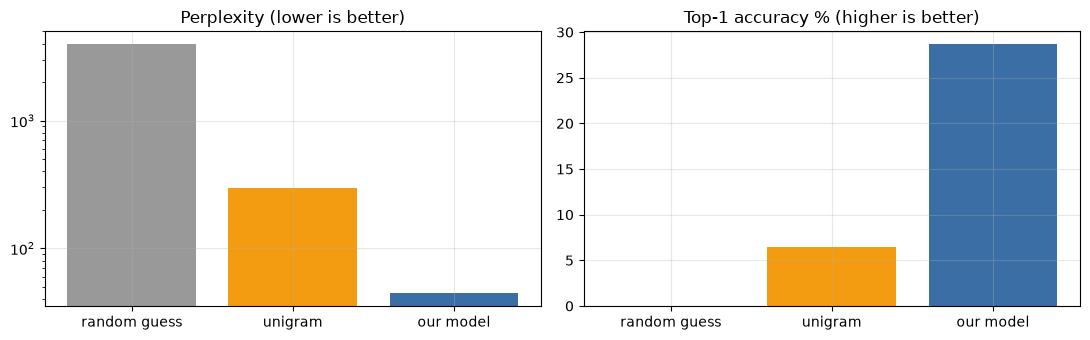

In [3]:
from collections import Counter
_, val = split_ids(tok.encode(load_corpus(DATA)))
train_ids, _ = split_ids(tok.encode(load_corpus(DATA)))
counts = Counter(train_ids.tolist())
total = sum(counts.values())
probs = {i: (counts.get(i, 0) + 1) / (total + tok.vocab_size) for i in range(tok.vocab_size)}   # add-one smoothing
unigram_loss = -sum(math.log(probs[i]) for i in val.tolist()) / len(val)
best_unigram_acc = (val == max(counts, key=counts.get)).float().mean().item()

names = ["random guess", "unigram", "our model"]
ppl = [tok.vocab_size, math.exp(unigram_loss), r.perplexity]
acc = [1 / tok.vocab_size, best_unigram_acc, r.accuracy]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(names, ppl, color=["#999", "#f39c12", "#3b6ea5"]); ax[0].set(yscale="log", title="Perplexity (lower is better)")
ax[1].bar(names, [a * 100 for a in acc], color=["#999", "#f39c12", "#3b6ea5"]); ax[1].set(title="Top-1 accuracy % (higher is better)")
plt.tight_layout()
for n, p, a in zip(names, ppl, acc):
    print(f"{n:13s} perplexity {p:8.1f}   accuracy {a:6.2%}")

## 3. Does context help? Loss by position

The first token of a window has **no context**; the 60th has 59 previous tokens. If the model uses attention properly,
the loss should fall as position grows. We compute the average loss at each position of the context window.

loss with 1 token of context: 4.43 | positions 10-64: 3.74


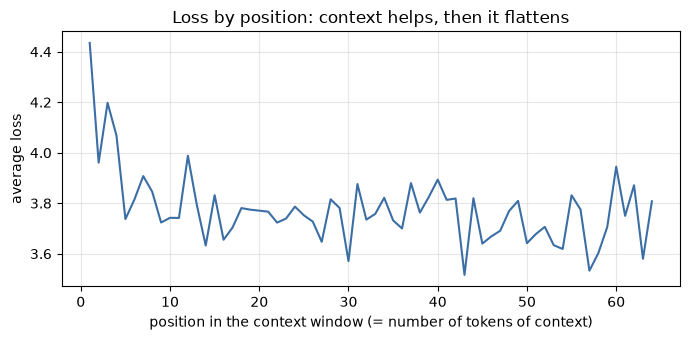

In [4]:
import torch.nn.functional as F
from myllm.data import CHUNK
block = model.cfg.block_size
# The validation set is made of separate 256-token chunks. Build windows *inside* a chunk so that every
# target really follows its context (a window must not predict the first word of an unrelated chunk).
chunks = val[: (len(val) // CHUNK) * CHUNK].view(-1, CHUNK)
starts = range(0, CHUNK - block, block)
x = torch.cat([chunks[:, s : s + block] for s in starts])
y = torch.cat([chunks[:, s + 1 : s + 1 + block] for s in starts])
model.eval()
with torch.no_grad():
    logits, _ = model(x)
loss_pos = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), reduction="none").view(len(x), block).mean(0)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, block + 1), loss_pos.numpy(), color="#3b6ea5")
plt.xlabel("position in the context window (= number of tokens of context)"); plt.ylabel("average loss")
plt.title("Loss by position: context helps, then it flattens"); plt.tight_layout()
print(f"loss with 1 token of context: {loss_pos[0]:.2f} | positions 10-{block}: {loss_pos[9:].mean():.2f}")

Reading the chart: with a single token of context the model is only slightly better than a bigram guess; after
about **5-10 tokens** the loss drops by ~0.7 and then stays flat. Our tiny model extracts most of its benefit from the
*recent* words; a 64-token window is more than it can use. (Bigger models and more training make use of longer context.)

## 4. Where does it fail? Hardest and easiest tokens

Aggregate numbers hide patterns. Let's see which target tokens the model finds hardest on average.

In [5]:
flat_y = y.reshape(-1); flat_loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), flat_y, reduction="none")
import collections
per_tok = collections.defaultdict(list)
for t, l in zip(flat_y.tolist(), flat_loss.tolist()):
    per_tok[t].append(l)
rows = [(tok.itos[t], sum(v) / len(v), len(v)) for t, v in per_tok.items() if len(v) >= 20]
rows.sort(key=lambda r: r[1])
print("EASIEST tokens (avg loss):", [(w, round(l, 2)) for w, l, _ in rows[:8]])
print("HARDEST tokens (avg loss):", [(w, round(l, 2)) for w, l, _ in rows[-8:]])

EASIEST tokens (avg loss): [('=', 0.17), ('>', 0.32), (':', 0.92), ('/', 1.34), ('and', 1.36), ('of', 1.37), ('<', 1.43), ('key', 1.49)]
HARDEST tokens (avg loss): [('flesh', 6.33), ('according', 6.37), ('yet', 6.4), ('many', 6.61), ('righteousness', 6.75), ('only', 6.91), ('where', 6.97), ('through', 7.34)]


What to look for:

* the **easiest** tokens include `=`, `<`, `>` and `/` — these are *not English*; they are leftover markup from the book's
  source format (lesson 1). Easy numbers are suspicious: **a model also learns the junk in your data**.
* `:` , `and` and `of` are easy for a real reason: after a verse number or a noun they are extremely predictable.
* the **hardest** tokens are ordinary content words (`through`, `where`, `only`, `many`...) that could follow almost anything —
  the model has to guess *which topic* comes next.

## 5. Evaluating your own text

`evaluate_text` scores any text — try it with a style the model never saw and watch perplexity rise.

In [6]:
from myllm.evaluate import evaluate_text
samples = {
  "bible-like": "and the lord said unto moses, go in unto pharaoh, and say unto him, thus saith the lord god of the hebrews, " * 3,
  "bitcoin-like": "a bitcoin transaction spends the outputs of earlier transactions, and miners add the transaction to a block of the blockchain. " * 3,
  "modern chat": "hey, what time do we meet tomorrow for lunch? i can bring my laptop and some snacks if you want to work together. " * 3,
}
for name, text in samples.items():
    e = evaluate_text(model, tok, text)
    print(f"{name:13s} perplexity {e.perplexity:8.1f}   accuracy {e.accuracy:6.1%}")

bible-like    perplexity      9.2   accuracy  57.8%
bitcoin-like  perplexity     55.1   accuracy  21.9%
modern chat   perplexity     80.5   accuracy  12.5%


---
## ✅ Key takeaways

- Always evaluate on held-out data; report perplexity AND compare to baselines.
- Beating the unigram baseline proves the model uses context.
- Loss falls as context grows (most of the gain in the first ~10 tokens for this small model).
- A model also learns formatting junk in the data: inspect the easiest tokens as well as the hardest.
- Out-of-domain text has much higher perplexity — a model only knows what it was trained on.

## 🧪 Exercises

1. Evaluate `lesson_tiny.pt` and `model.pt` (if you have both) on the same text. By how much does perplexity drop?
2. The loss-by-position curve flattens after ~10 tokens. What does that suggest about the value of a longer context window for *this* model?
3. Write three sentences of your own and rank them by perplexity. Predict the order before running.

## ➡️ Next

**Lesson 7 — Experiments:** changing the model and measuring what helps.